# Sentiment Analysis Using PySpark: TF-IDF + Logistic Regression

**Dataset:** `train_data.csv`  
**Columns:** `sentence`, `sentiment`  
**Labels:** `0 = Negative`, `1 = Positive`

This version adapts the project to your dataset and uses:
1. CSV parsing and initial preprocessing with RDDs
2. Text cleaning and filler-word removal
3. Tokenization and stop-word removal
4. `CountVectorizer` followed by `IDF` to create TF-IDF features
5. A 70/30 train/test split
6. Spark MLlib Logistic Regression with `maxIter=10` and `regParam=0.01`
7. Accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix

The model remains Logistic Regression, but changing from `HashingTF` to TF-IDF changes the features, so the accuracy will need to be measured again. This notebook uses Spark DataFrames for the MLlib feature pipeline and model, because those APIs require DataFrame input.


In [28]:
%pip -q install pyspark

In [ ]:
from pyspark import SparkContext
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when
from pyspark.ml import Pipeline
from pyspark.ml.feature import Tokenizer, StopWordsRemover, CountVectorizer, IDF
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.mllib.evaluation import MulticlassMetrics
import csv
import re
import matplotlib.pyplot as plt

In [ ]:
sc = SparkContext.getOrCreate()
sc.setLogLevel("ERROR")
spark = SparkSession.builder.getOrCreate()

In [ ]:
file_path = "/content/train_data.csv"
raw_rdd = sc.textFile(file_path)
header = raw_rdd.first()
print("Header:", header)
print("Sample raw lines:")
for line in raw_rdd.take(5):
    print(line)

Header: sentence,sentiment
Sample raw lines:
sentence,sentiment
awww that s a bummer you shoulda got david carr of third day to do it d,0
is upset that he can t update his facebook by texting it and might cry as a result school today also blah,0
i dived many times for the ball managed to save the rest go out of bounds,0
my whole body feels itchy and like its on fire,0


In [31]:
def parse_record(line):
    try:
        row = next(csv.reader([line]))
        if len(row) < 2:
            return None
        sentence = row[0].strip()
        label_text = row[-1].strip()
        if not sentence:
            return None

        label = int(label_text)
        if label not in (0, 1):
            return None

        return (sentence, float(label))
    except (ValueError, csv.Error, IndexError):
        return None

records = (
    raw_rdd
    .filter(lambda line: line != header)
    .map(parse_record)
    .filter(lambda x: x is not None)
    .cache()
)

print("First parsed records:", records.take(5))
print("Valid record count:", records.count())
print("Label counts (0=Negative, 1=Positive):",
      records.map(lambda x: (int(x[1]), 1)).reduceByKey(lambda a, b: a + b).collect())

if records.isEmpty():
    raise ValueError("No records parsed. Check the file path, CSV format, and numeric labels.")


First parsed records: [('awww that s a bummer you shoulda got david carr of third day to do it d', 0.0), ('is upset that he can t update his facebook by texting it and might cry as a result school today also blah', 0.0), ('i dived many times for the ball managed to save the rest go out of bounds', 0.0), ('my whole body feels itchy and like its on fire', 0.0), ('no it s not behaving at all i m mad why am i here because i can t see you all over there', 0.0)]
Valid record count: 1523863
Label counts (0=Negative, 1=Positive): [(0, 767023), (1, 756840)]


In [32]:
filler_words = {
    "uh", "um", "erm", "hmm", "ah", "actually", "basically", "literally"
}

def clean_sentence(sentence):
    text = sentence.lower()
    text = re.sub(r"https?://\S+|www\\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"[^a-zA-Z'\s]", " ", text)
    tokens = text.split()
    tokens = [word for word in tokens if word not in filler_words]
    return " ".join(tokens)

clean_records = records.map(
    lambda x: (clean_sentence(x[0]), x[1])
).filter(lambda x: len(x[0].strip()) > 0).cache()

print("Cleaned examples:")
print(clean_records.take(5))
print("Records after cleaning:", clean_records.count())


Cleaned examples:
[('awww that s a bummer you shoulda got david carr of third day to do it d', 0.0), ('is upset that he can t update his facebook by texting it and might cry as a result school today also blah', 0.0), ('i dived many times for the ball managed to save the rest go out of bounds', 0.0), ('my whole body feels itchy and like its on fire', 0.0), ('no it s not behaving at all i m mad why am i here because i can t see you all over there', 0.0)]
Records after cleaning: 1523853


In [33]:
data = spark.createDataFrame(clean_records, ["sentence", "label"])

train, test = data.randomSplit([0.7, 0.3], seed=42)
train = train.cache()
test = test.cache()

print("Training records:", train.count())
print("Testing records:", test.count())
print("Training labels:")
train.groupBy("label").count().show()
print("Testing labels:")
test.groupBy("label").count().show()

if train.count() == 0 or test.count() == 0:
    raise ValueError("Training or testing split is empty.")


Training records: 1066861
Testing records: 456992
Training labels:
+-----+------+
|label| count|
+-----+------+
|  0.0|536941|
|  1.0|529920|
+-----+------+

Testing labels:
+-----+------+
|label| count|
+-----+------+
|  0.0|230079|
|  1.0|226913|
+-----+------+



In [34]:
tokenizer = Tokenizer(inputCol="sentence", outputCol="tokens")

stop_word_remover = StopWordsRemover(
    inputCol="tokens",
    outputCol="filtered_tokens"
)

# Keep sentiment-critical negations.
default_stop_words = set(stop_word_remover.getStopWords())
stop_word_remover.setStopWords([
    word for word in default_stop_words
    if word not in {"no", "not", "nor"}
])

print("Tokenizer and stop-word remover configured.")


Tokenizer and stop-word remover configured.


In [35]:
count_vectorizer = CountVectorizer(
    inputCol="filtered_tokens",
    outputCol="raw_features",
    vocabSize=50000,
    minDF=2.0
)
idf = IDF(inputCol="raw_features", outputCol="features")


In [36]:
lr = LogisticRegression(
    labelCol="label",
    featuresCol="features",
    maxIter=10,
    regParam=0.01
)

pipeline = Pipeline(stages=[
    tokenizer,
    stop_word_remover,
    count_vectorizer,
    idf,
    lr
])

model = pipeline.fit(train)
print("Training complete.")


Training complete.


In [37]:
predictions = model.transform(test).cache()

predictions.select(
    "sentence", "label", "prediction", "probability"
).show(10, truncate=80)

print("Test predictions:", predictions.count())


+--------------------------------------------------------------------------------+-----+----------+-----------------------------------------+
|                                                                        sentence|label|prediction|                              probability|
+--------------------------------------------------------------------------------+-----+----------+-----------------------------------------+
|                                             a always work when we get warm days|  0.0|       0.0|  [0.5073529961092127,0.4926470038907873]|
|                                            a baby bird that fell from it s nest|  0.0|       0.0| [0.8047060985036467,0.19529390149635328]|
|a baby llama was born last week she is adorable the emus are silly tibby the ...|  0.0|       1.0| [0.13851775074978592,0.8614822492502141]|
|                                                 a baby with cancer how terrible|  0.0|       0.0| [0.8848840550101215,0.11511594498987854]|
|     

In [38]:
# MulticlassMetrics expects (prediction, label) pairs.
prediction_and_label = predictions.select("prediction", "label").rdd.map(
    lambda row: (float(row["prediction"]), float(row["label"]))
)
metrics = MulticlassMetrics(prediction_and_label)

accuracy = metrics.accuracy
precision_positive = metrics.precision(1.0)
recall_positive = metrics.recall(1.0)
f1_positive = metrics.fMeasure(1.0)
precision_negative = metrics.precision(0.0)
recall_negative = metrics.recall(0.0)
f1_negative = metrics.fMeasure(0.0)
confusion = metrics.confusionMatrix().toArray()

print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Positive precision: {precision_positive:.4f}")
print(f"Positive recall:    {recall_positive:.4f}")
print(f"Positive F1-score:  {f1_positive:.4f}")
print(f"Negative precision: {precision_negative:.4f}")
print(f"Negative recall:    {recall_negative:.4f}")
print(f"Negative F1-score:  {f1_negative:.4f}")
print("Confusion matrix (rows=actual [0,1], columns=predicted [0,1]):")
print(confusion)


/usr/local/lib/python3.13/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


Accuracy: 77.77%
Positive precision: 0.7669
Positive recall:    0.7935
Positive F1-score:  0.7800
Negative precision: 0.7891
Negative recall:    0.7621
Negative F1-score:  0.7754
Confusion matrix (rows=actual [0,1], columns=predicted [0,1]):
[[175353.  54726.]
 [ 46863. 180050.]]


In [39]:
evaluator = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)
roc_auc = evaluator.evaluate(predictions)
print(f"ROC-AUC: {roc_auc:.4f}")


ROC-AUC: 0.8489


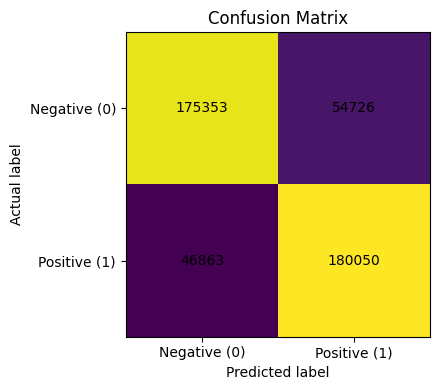

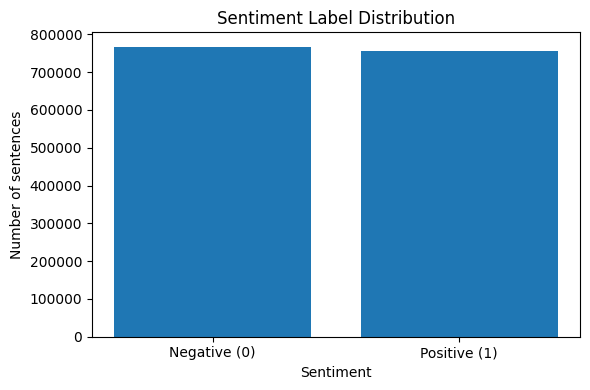

In [40]:
plt.figure(figsize=(5, 4))
plt.imshow(confusion, interpolation="nearest")
plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.xticks([0, 1], ["Negative (0)", "Positive (1)"])
plt.yticks([0, 1], ["Negative (0)", "Positive (1)"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, int(confusion[i, j]), ha="center", va="center")
plt.tight_layout()
plt.show()

label_counts = data.groupBy("label").count().orderBy("label").collect()
labels = ["Negative (0)" if row["label"] == 0 else "Positive (1)" for row in label_counts]
counts = [row["count"] for row in label_counts]

plt.figure(figsize=(6, 4))
plt.bar(labels, counts)
plt.title("Sentiment Label Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of sentences")
plt.tight_layout()
plt.show()


In [41]:
model_path = "/content/sentiment_tfidf_logistic_pipeline"
model.write().overwrite().save(model_path)
print("Saved pipeline to:", model_path)


Saved pipeline to: /content/sentiment_tfidf_logistic_pipeline


In [42]:
def predict_sentiment(sentence):
    cleaned_sentence = clean_sentence(sentence)
    sample = spark.createDataFrame([(cleaned_sentence,)], ["sentence"])
    result = model.transform(sample).select("prediction", "probability").first()
    label = "Positive" if int(result["prediction"]) == 1 else "Negative"
    positive_probability = float(result["probability"][1])
    return {
        "sentiment": label,
        "positive_probability": round(positive_probability, 4)
    }

print(predict_sentiment("I absolutely love this product"))
print(predict_sentiment("This is terrible and I hate it"))


{'sentiment': 'Positive', 'positive_probability': 0.8548}
{'sentiment': 'Negative', 'positive_probability': 0.0703}


In [43]:
import os
import shutil
from google.colab import files

model_path = "/content/sentiment_tfidf_logistic_pipeline"

# Save the complete trained pipeline
model.write().overwrite().save(model_path)

# Compress the model directory
zip_path = shutil.make_archive(
    "/content/sentiment_tfidf_logistic_pipeline",
    "zip",
    root_dir="/content",
    base_dir="sentiment_tfidf_logistic_pipeline"
)

print("Model saved successfully!")
print("ZIP file:", zip_path)

# Download to your computer
files.download(zip_path)

Model saved successfully!
ZIP file: /content/sentiment_tfidf_logistic_pipeline.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
predictions.unpersist()
train.unpersist()
test.unpersist()
records.unpersist()
clean_records.unpersist()
sc.stop()
spark.stop()
